---------- Solver info
Time scale coeff:       1.00e-02
dx:                     6.67e-03
dt:                     2.00e-05
nt:                     50000
nx:                     16
r:                      4.50e-01


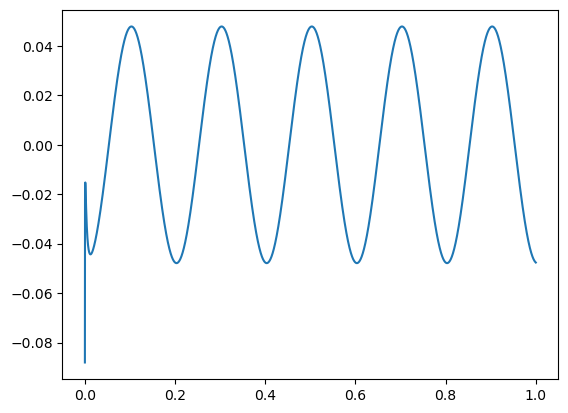

In [37]:
from generate_f_from_white_noise import *
import heat1D_crank_nicolson_solver as cns

np.random.seed(42)

# Parametri simulazione
L = 0.1
Tf = 1
nt = 50000
D = 1
wanted_r = 0.5
h = 1

solver = cns.Heat1DCrankNicolson(L,Tf,nt,D,h)
solver.info()

# Compute total heat
def compute_Q(T, dx):
    return dx * (0.5*T[0] + np.sum(T[1:-1]) + 0.5*T[-1])

def flux_left(T, dx):
    return (-3*T[0] + 4*T[1] - T[2]) / (2*dx)

def flux_right(T, h):
    return -h * T[-1]

def check_balance(Tn, Tnp1, dx, dt, D, h):
    Qn   = compute_Q(Tn, dx)
    Qnp1 = compute_Q(Tnp1, dx)

    dQdt_num = (Qnp1 - Qn) / dt

    # flussi al tempo n
    flux_L_n = flux_left(Tn, dx)
    flux_R_n = flux_right(Tn, h)

    # flussi al tempo n+1
    flux_L_np1 = flux_left(Tnp1, dx)
    flux_R_np1 = flux_right(Tnp1, h)

    # media Crank–Nicolson
    flux_L = 0.5 * (flux_L_n + flux_L_np1)
    flux_R = 0.5 * (flux_R_n + flux_R_np1)

    dQdt_theory = D * (flux_R - flux_L)

    return dQdt_num, dQdt_theory

f = np.sin(2*np.pi/Tf*solver.t_array*5)

T = solver.solve(f)

dQdt_num_array = np.ndarray(solver.nt-1)
dQdt_theory_array = np.ndarray(solver.nt-1)

for i in range(solver.nt-1):
    dQdt_num, dQdt_theory = check_balance(T[:,i], T[:,i+1], solver.dx, solver.dt, D, h)
    dQdt_num_array[i] = dQdt_num
    dQdt_theory_array[i] = dQdt_theory

plt.plot(solver.t_array[:-1], dQdt_theory_array-dQdt_num_array)
